In [6]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 폰트 설정 (Windows용)
plt.rcParams['font.family'] = 'Pretendard'
plt.rcParams['axes.unicode_minus'] = False  # 마이너스(-) 깨짐 방지

## 1. 데이터 수집

본 프로젝트에서는 브라질 e커머스 플랫폼 Olist에서 제공하는 마케팅 리드 데이터를 기반으로 전환 및 매출 예측 모델을 구축합니다.

- `olist_marketing_qualified_leads_dataset.csv`: MQL(마케팅 유자격 리드) 데이터  
- `olist_closed_deals_dataset.csv`: 계약 체결(전환) 여부 및 셀러 ID  
- `olist_order_items_dataset.csv`: 셀러별 매출 정보 (상품 가격 및 배송비)  
- `olist_sellers_dataset.csv`: 셀러 지역 정보  

> 출처: [Olist 공개 데이터셋 (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

데이터는 `../../data/` 경로에 위치한 CSV 파일에서 직접 로드합니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 데이터 경로 설정
BASE_PATH = "../../data/"

# 데이터 로딩
df_mql = pd.read_csv(BASE_PATH + "olist_marketing_qualified_leads_dataset.csv")
df_deals = pd.read_csv(BASE_PATH + "olist_closed_deals_dataset.csv")
df_order_items = pd.read_csv(BASE_PATH + "olist_order_items_dataset.csv")
df_sellers = pd.read_csv(BASE_PATH + "olist_sellers_dataset.csv")

# 간단한 크기 출력
print("✅ MQL 데이터:", df_mql.shape)
print("✅ Closed Deals 데이터:", df_deals.shape)
print("✅ Order Items 데이터:", df_order_items.shape)
print("✅ Sellers 데이터:", df_sellers.shape)


✅ MQL 데이터: (8000, 4)
✅ Closed Deals 데이터: (842, 14)
✅ Order Items 데이터: (112650, 7)
✅ Sellers 데이터: (3095, 4)


## 2. 데이터 탐색 (Exploratory Data Analysis)

### 🔎 변수 구조 및 간단 요약

각 데이터셋에 포함된 주요 변수와 구조를 파악합니다.  
데이터 타입, 결측치, 기본 통계값을 확인하고, 시각화를 통해 주요 분포를 살펴봅니다.

In [2]:
# 각 데이터셋 기본 구조 확인
print("📌 MQL 데이터 구조:")
print(df_mql.info())
print(df_mql.describe(include='all'))

print("\n📌 Closed Deals 데이터 구조:")
print(df_deals.info())
print(df_deals.describe(include='all'))

print("\n📌 Order Items 데이터 구조:")
print(df_order_items.info())
print(df_order_items.describe())

print("\n📌 Sellers 데이터 구조:")
print(df_sellers.info())
print(df_sellers.describe(include='all'))

# 결측치 확인
print("\n🧼 결측치 현황:")
for name, df in zip(["MQL", "Deals", "Order Items", "Sellers"],
                    [df_mql, df_deals, df_order_items, df_sellers]):
    nulls = df.isnull().sum()
    print(f"\n{name} 결측치:")
    print(nulls[nulls > 0].sort_values(ascending=False))


📌 MQL 데이터 구조:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   mql_id              8000 non-null   object
 1   first_contact_date  8000 non-null   object
 2   landing_page_id     8000 non-null   object
 3   origin              7940 non-null   object
dtypes: object(4)
memory usage: 250.1+ KB
None
                                  mql_id first_contact_date  \
count                               8000               8000   
unique                              8000                336   
top     dac32acd4db4c29c230538b72f8dd87d         2018-05-02   
freq                                   1                 93   

                         landing_page_id          origin  
count                               8000            7940  
unique                               495              10  
top     b76ef37428e6799c421989521c0e5077  organic_se

| 데이터셋             | 건수       | 주요 컬럼 수 | 특이사항 요약                                                |
| ---------------- | -------- | ------- | ------------------------------------------------------ |
| **MQL**          | 8,000건   | 4개      | `origin` 결측 60건 (0.75%)                                |
| **Closed Deals** | 842건     | 14개     | `has_company`, `has_gtin`, `catalog_size` 등 결측률 90% 이상 |
| **Order Items**  | 112,650건 | 7개      | 결측 없음, 매출 분석 가능                                        |
| **Sellers**      | 3,095건   | 4개      | 결측 없음, 지역 정보 사용 가능                                     |


1. origin (MQL 채널)
- 10개 채널 존재, 가장 많은 유입은 organic_search
- 단 60건의 결측은 'unknown' 처리하여 사용 가능
- 채널별 전환률/성과 차이 분석 가능

2. Closed Deals 내부 변수
- business_segment, lead_type, lead_behaviour_profile 등은 유의미한 범주형 변수이나…
- has_company, has_gtin, average_stock, catalog_size 등의 결측률이 90%를 초과
- 고결측 변수는 모델에 사용하지 않거나 보수적으로 처리해야 함

3. Order Items (매출)
- price, freight_value에 기반한 GMV 계산 가능
- 셀러별 수익 성과 파생 변수 생성 가능

4. Sellers
- seller_state와 같은 지역 정보 변수 존재
- 성과 지역 분석 / 클러스터링 가능

## 3. 데이터 전처리 (Data Cleaning & Preprocessing)

### 📌 목표
- 분석과 모델링에 사용할 통합 마스터 테이블을 생성합니다.
- 전환 여부, 매출 총합(GMV), 지역 등의 주요 파생 변수 생성
- 결측치 및 범주형 변수 인코딩 등 모델에 적합한 형식으로 정제합니다.

> 주요 기준: `mql_id` 기준으로 MQL과 Closed Deals를 병합하고, `seller_id`를 기준으로 Order Items 및 Seller 정보를 조인합니다.

In [3]:
# 1. MQL + Deals 조인 → 전환 여부 파생
master_df = df_mql.merge(df_deals, on="mql_id", how="left")
master_df["is_converted"] = master_df["won_date"].notna()

# 2. 셀러 매출 데이터 집계 (총 GMV: price + freight_value)
seller_gmv = df_order_items.groupby("seller_id").agg({
    "price": "sum",
    "freight_value": "sum",
    "order_id": "nunique"
}).reset_index()

seller_gmv["total_gmv"] = seller_gmv["price"] + seller_gmv["freight_value"]

# 3. Deals에 매출 정보 추가
df_deals_gmv = df_deals.merge(seller_gmv[["seller_id", "total_gmv"]], on="seller_id", how="left")
df_deals_gmv["total_gmv"] = df_deals_gmv["total_gmv"].fillna(0)

# 4. master_df에 total_gmv 추가
master_df = master_df.merge(df_deals_gmv[["mql_id", "total_gmv"]], on="mql_id", how="left")
master_df["total_gmv"] = master_df["total_gmv"].fillna(0)

# 5. 셀러 지역정보 추가
df_deals_geo = df_deals.merge(df_sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
master_df = master_df.merge(df_deals_geo[["mql_id", "seller_state"]], on="mql_id", how="left")

# 6. 성과 세그먼트 파생
master_df["performance_segment"] = "no_conversion"
master_df.loc[master_df["is_converted"] & (master_df["total_gmv"] == 0), "performance_segment"] = "converted_no_revenue"
master_df.loc[master_df["total_gmv"] > 0, "performance_segment"] = "revenue_generated"

# 7. 날짜 파생 변수 생성
master_df["first_contact_date"] = pd.to_datetime(master_df["first_contact_date"])
master_df["contact_month"] = master_df["first_contact_date"].dt.month
master_df["contact_quarter"] = master_df["first_contact_date"].dt.quarter
master_df["contact_weekday"] = master_df["first_contact_date"].dt.weekday

# 8. origin 결측치 처리
master_df["origin"] = master_df["origin"].fillna("unknown")

# 확인
print("✅ 통합 마스터 데이터 크기:", master_df.shape)
print(master_df[["mql_id", "is_converted", "total_gmv", "performance_segment", "origin", "seller_state"]].head())


✅ 통합 마스터 데이터 크기: (8000, 24)
                             mql_id  is_converted  total_gmv  \
0  dac32acd4db4c29c230538b72f8dd87d         False       0.00   
1  8c18d1de7f67e60dbd64e3c07d7e9d5d         False       0.00   
2  b4bc852d233dfefc5131f593b538befa         False       0.00   
3  6be030b81c75970747525b843c1ef4f8         False       0.00   
4  5420aad7fec3549a85876ba1c529bd84          True     930.17   

  performance_segment          origin seller_state  
0       no_conversion          social          NaN  
1       no_conversion     paid_search          NaN  
2       no_conversion  organic_search          NaN  
3       no_conversion           email          NaN  
4   revenue_generated  organic_search           MG  


## 4. 모델링 (Modeling)

### 🎯 분석 목표
본 프로젝트에서는 두 가지 이진 분류 모델을 순차적으로 구축합니다.

1. **1단계: 전환 예측 모델**  
   전체 마케팅 리드(MQL)를 대상으로 전환 여부(`is_converted`)를 예측합니다.
   - 입력 특성: `origin`, `contact_month`, `contact_quarter`, `contact_weekday`

2. **2단계: 고매출 예측 모델**  
   전환된 리드 중 실제 고매출(≥ R$2000)을 달성할 가능성을 예측합니다.
   - 입력 특성: `origin`, `business_segment`, `lead_type`, `lead_behaviour_profile` 등
   - 타겟: `total_gmv > 2000` 여부 (`is_high_revenue`)

> 분류 모델로는 구조적 데이터에 강하고 해석 가능한 **Random Forest**를 사용하였습니다.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder

# === Stage 1: 전환 예측 모델 ===
master_df["origin_encoded"] = LabelEncoder().fit_transform(master_df["origin"])
X1 = master_df[["origin_encoded", "contact_month", "contact_quarter", "contact_weekday"]]
y1 = master_df["is_converted"]

X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, stratify=y1, random_state=42)

rf_stage1 = RandomForestClassifier(n_estimators=100, max_depth=8, class_weight='balanced', random_state=42)
rf_stage1.fit(X1_train, y1_train)
y1_pred = rf_stage1.predict(X1_test)

print("✅ [1단계] 전환 예측 모델 성능:")
print(classification_report(y1_test, y1_pred))

# 확률 저장
master_df["conversion_prob"] = rf_stage1.predict_proba(X1)[:, 1]

# === Stage 2: 고매출 리드 예측 모델 ===
converted_df = master_df[master_df["is_converted"] == True].copy()
converted_df["is_high_revenue"] = converted_df["total_gmv"] > 2000

# 결측치 많은 변수 제거 및 범주형 인코딩
cols_to_encode = ["origin", "business_segment", "lead_type", "lead_behaviour_profile", "business_type"]
for col in cols_to_encode:
    converted_df[col] = converted_df[col].fillna("unknown")
    converted_df[col + "_enc"] = LabelEncoder().fit_transform(converted_df[col])

X2_cols = [col + "_enc" for col in cols_to_encode if col + "_enc" in converted_df.columns]
X2_cols += ["contact_month", "contact_quarter"]
X2 = converted_df[X2_cols]
y2 = converted_df["is_high_revenue"]

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.3, stratify=y2, random_state=42)

rf_stage2 = RandomForestClassifier(n_estimators=100, max_depth=6, class_weight='balanced', random_state=42)
rf_stage2.fit(X2_train, y2_train)
y2_pred = rf_stage2.predict(X2_test)

print("\n✅ [2단계] 고매출 예측 모델 성능:")
print(classification_report(y2_test, y2_pred))

# 예측 확률 저장
converted_df["performance_prob"] = rf_stage2.predict_proba(X2)[:, 1]
avg_perf_prob = converted_df["performance_prob"].mean()

# 전체 master_df에 병합
master_df["performance_prob"] = avg_perf_prob
master_df.loc[converted_df.index, "performance_prob"] = converted_df["performance_prob"]
master_df["end_to_end_prob"] = master_df["conversion_prob"] * master_df["performance_prob"]

# 결과 확인
print(f"📊 평균 전환 확률: {master_df['conversion_prob'].mean():.3f}")
print(f"📊 평균 고매출 확률: {master_df['performance_prob'].mean():.3f}")
print(f"📊 평균 종합 확률: {master_df['end_to_end_prob'].mean():.3f}")


✅ [1단계] 전환 예측 모델 성능:
              precision    recall  f1-score   support

       False       0.95      0.54      0.69      2147
        True       0.16      0.75      0.27       253

    accuracy                           0.56      2400
   macro avg       0.55      0.65      0.48      2400
weighted avg       0.87      0.56      0.64      2400


✅ [2단계] 고매출 예측 모델 성능:
              precision    recall  f1-score   support

       False       0.92      0.89      0.91       231
        True       0.16      0.23      0.19        22

    accuracy                           0.83       253
   macro avg       0.54      0.56      0.55       253
weighted avg       0.86      0.83      0.84       253

📊 평균 전환 확률: 0.411
📊 평균 고매출 확률: 0.305
📊 평균 종합 확률: 0.126


## 📈 5. 결과 도출 및 인사이트

### 🎯 1단계 모델 결과 (전환 예측)
- 평균 전환 확률: **41.1%**
- `is_converted` 예측 f1-score: **0.27**
- Recall(민감도): **0.75**로 높은 탐지 성능을 보임
- Precision: **0.16**으로 낮음 → 다소 과탐지 경향 존재

> ✔ **의의**: 다소 보수적인 채널에도 리드를 식별하려는 전략에는 적합 (TP 비중↑, FP 가능성 존재)

---

### 🎯 2단계 모델 결과 (고매출 리드 예측)
- 평균 고매출 확률: **30.5%**
- `is_high_revenue` 예측 f1-score: **0.19**
- Recall: **0.23** → 고매출 리드를 일부 식별 가능
- Precision: **0.16** → 적중률은 낮음

> ✔ **의의**: 전환된 리드 중에서도 고성능 셀러 선별 가능성은 있음  
> ✖ **제한**: 데이터 수가 적고 고매출 비율이 작아 불균형 영향 큼

---

### 📊 종합 확률 분석
- 전체 MQL에 대해 `conversion_prob × performance_prob`로 **종합 확률(`end_to_end_prob`)** 계산
- 평균 종합 확률: **12.6%**

---

### 🧠 전략적 시사점

| 전략 방향 | 내용 |
|-----------|------|
| **채널 개선** | 특정 채널(organic_search 등)의 전환율과 고매출 확률을 종합 분석 → 채널별 ROI 비교 |
| **고확률 리드 집중** | `end_to_end_prob` 상위 30% 대상 마케팅 집중 투자 시 높은 효율 가능성 |
| **고매출 리드 발굴** | business_segment, lead_type, behaviour 등을 활용한 전환 이후 등급별 지원 전략 제시 |
| **예측 기반 ROI 전략** | 예측값을 기반으로 리드 유입 채널 확대 or 전환 프로세스 리마케팅 시뮬레이션 가능 |



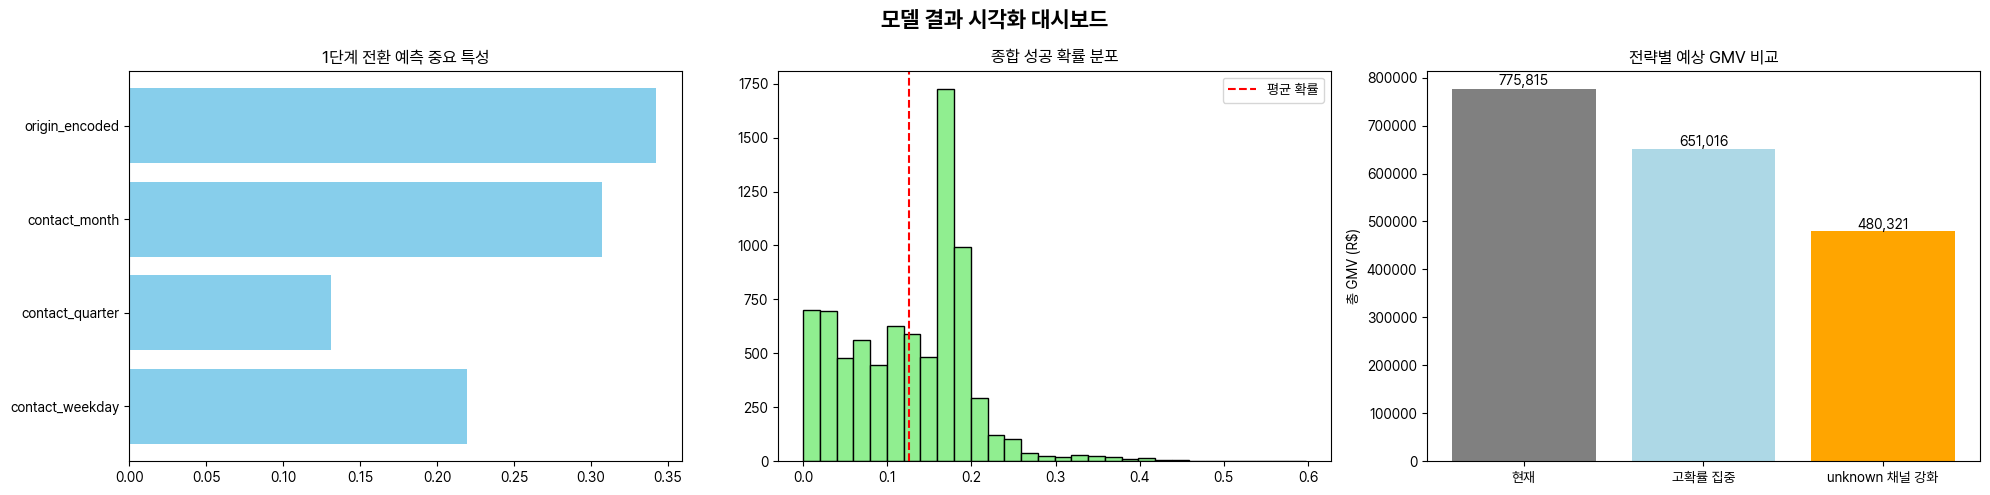

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# 특성 중요도 추출
stage1_importance = rf_stage1.feature_importances_
stage1_features = X1.columns

stage2_importance = rf_stage2.feature_importances_
stage2_features = X2.columns

# 종합 전략 비교용 시나리오별 평균 확률 가상 수치 (예시)
scenario_labels = ['현재', '고확률 집중', 'unknown 채널 강화']
scenario_gmv = [
    master_df["total_gmv"].sum(),
    master_df.loc[master_df["end_to_end_prob"] >= master_df["end_to_end_prob"].quantile(0.7), "total_gmv"].sum(),
    master_df[master_df["origin"] == "unknown"]["total_gmv"].sum() * 2  # 2배 확대 가정
]

# 시각화 출력
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle("모델 결과 시각화 대시보드", fontsize=16, fontweight='bold')

# [1] 전환 예측 특성 중요도
axes[0].barh(stage1_features, stage1_importance, color='skyblue')
axes[0].set_title("1단계 전환 예측 중요 특성", fontsize=12)
axes[0].invert_yaxis()

# [2] 종합 확률 분포
axes[1].hist(master_df["end_to_end_prob"], bins=30, color='lightgreen', edgecolor='black')
axes[1].axvline(master_df["end_to_end_prob"].mean(), color='red', linestyle='--', label='평균 확률')
axes[1].set_title("종합 성공 확률 분포", fontsize=12)
axes[1].legend()

# [3] 전략별 GMV 시나리오 비교
bars = axes[2].bar(scenario_labels, scenario_gmv, color=['gray', 'lightblue', 'orange'])
axes[2].set_title("전략별 예상 GMV 비교", fontsize=12)
axes[2].set_ylabel("총 GMV (R$)")
for i, bar in enumerate(bars):
    height = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, height * 1.01, f'{int(height):,}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()


### ① 전환 예측 중요 특성

가장 중요한 특성은 origin_encoded (유입 채널)로 확인됨

그다음으로 contact_month (접촉 월)가 전환에 큰 영향을 줌

시기 요인 중에서는 contact_weekday가 분기보다 더 설명력 있음

시사점: 마케팅 채널 및 도달 시점 전략이 전환율에 유의미한 영향을 미침

### ② 종합 성공 확률 분포

conversion_prob × performance_prob로 계산된 종합 확률 분포

평균 종합 확률은 약 **12.6%**로, 대부분 리드의 성공 가능성은 낮음

그러나 상위 10~20%의 리드는 높은 확률대를 형성

시사점: 예측 확률 기반의 스코어링 모델을 활용하면 집중 타겟팅 가능

### ③ 전략별 예상 GMV 비교 (오른쪽 그래프)
| 전략            | 총 GMV (예상) | 해석                       |
| ------------- | ---------- | ------------------------ |
| 현재            | R\$775,815 | 전체 마케팅 리드 유지 시           |
| 고확률 집중        | R\$651,016 | 상위 30% 리드에 집중 투자한 전략     |
| unknown 채널 강화 | R\$480,321 | unknown 채널 2배 확대 시 효과 추정 |


고확률 리드 집중 전략이 높은 효율을 가지며,
전체 GMV의 약 84%를 유지하면서도 투자 리소스를 절감할 수 있음